# 2. Classification: 1-NN with different similarities

In [1]:
import sys
sys.path.insert(0, "..")
import json
import numpy as np
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from sklearn.metrics import accuracy_score
from tslearn.neighbors import KNeighborsTimeSeriesClassifier
from mldtw.simulate import make_dataset, centre

/tmp/claude-6022/-obs-ddehiwalage-don-microlensing-application/e5c22c67-9554-4daa-b0c8-8ca5c61a4549/scratchpad/venv/lib/python3.13/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)


In [2]:
X_train, y_train, _ = make_dataset(40, seed=3)
X_test, y_test, _ = make_dataset(30, seed=4)
Xc_train, Xc_test = centre(X_train), centre(X_test)

In [3]:
band = {"global_constraint": "sakoe_chiba", "sakoe_chiba_radius": 24}
metrics = {
    "Euclid": (False, "euclidean", {}),
    "Euclid, centred": (True, "euclidean", {}),
    "DTW": (False, "dtw", {}),
    "DTW band": (False, "dtw", band),
    "Centred + DTW": (True, "dtw", {}),
    "Centred + DTW band": (True, "dtw", band),
}
for g in [0.01, 0.1, 1, 10]:
    metrics[f"Centred soft-DTW, gamma={g}"] = (True, "softdtw", {"gamma": g})

In [4]:
def accuracy(centred, metric, params):
    A, B = (Xc_train, Xc_test) if centred else (X_train, X_test)
    knn = KNeighborsTimeSeriesClassifier(n_neighbors=1, metric=metric, metric_params=params)
    knn.fit(A, y_train)
    return accuracy_score(y_test, knn.predict(B))

scores = Parallel(n_jobs=len(metrics))(delayed(accuracy)(*m) for m in metrics.values())
acc = dict(zip(metrics, scores))
json.dump(acc, open("../results/accuracy.json", "w"), indent=1)
acc

/tmp/claude-6022/-obs-ddehiwalage-don-microlensing-application/e5c22c67-9554-4daa-b0c8-8ca5c61a4549/scratchpad/venv/lib/python3.13/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)
/tmp/claude-6022/-obs-ddehiwalage-don-microlensing-application/e5c22c67-9554-4daa-b0c8-8ca5c61a4549/scratchpad/venv/lib/python3.13/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)
/tmp/claude-6022/-obs-ddehiwalage-don-microlensing-application/e5c22c67-9554-4daa-b0c8-8ca5c61a4549/scratchpad/venv/lib/python3.13/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)


/tmp/claude-6022/-obs-ddehiwalage-don-microlensing-application/e5c22c67-9554-4daa-b0c8-8ca5c61a4549/scratchpad/venv/lib/python3.13/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)
/tmp/claude-6022/-obs-ddehiwalage-don-microlensing-application/e5c22c67-9554-4daa-b0c8-8ca5c61a4549/scratchpad/venv/lib/python3.13/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)
/tmp/claude-6022/-obs-ddehiwalage-don-microlensing-application/e5c22c67-9554-4daa-b0c8-8ca5c61a4549/scratchpad/venv/lib/python3.13/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)
/tmp/claude-6022/-obs-ddehiwalage-don-microlensing-a

{'Euclid': 0.7066666666666667,
 'Euclid, centred': 0.9133333333333333,
 'DTW': 0.9533333333333334,
 'DTW band': 0.9133333333333333,
 'Centred + DTW': 0.9466666666666667,
 'Centred + DTW band': 0.9533333333333334,
 'Centred soft-DTW, gamma=0.01': 0.9266666666666666,
 'Centred soft-DTW, gamma=0.1': 0.8733333333333333,
 'Centred soft-DTW, gamma=1': 0.8333333333333334,
 'Centred soft-DTW, gamma=10': 0.8}

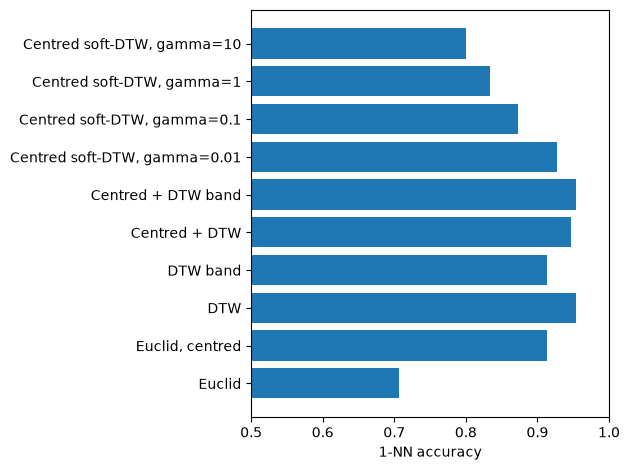

In [5]:
plt.barh(list(acc), list(acc.values()))
plt.xlim(0.5, 1)
plt.xlabel("1-NN accuracy")
plt.tight_layout()
plt.savefig("../figures/accuracy.png", dpi=150)